In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Load CSV
csv_data = pd.read_csv("sales.csv")

# Load Excel
excel_data = pd.read_excel("sales.xlsx")

# Load JSON
json_data = pd.read_json("sales.json")

print("CSV DATA")
print(csv_data.head())

print("\nEXCEL DATA")
print(excel_data.head())

print("\nJSON DATA")
print(json_data.head())

CSV DATA
   Order_ID       Product     Category  Quantity  Unit_Price  Order_Date  \
0      1001        Laptop  Electronics         2       55000  2026-01-03   
1      1002         Mouse  Accessories         5         800  2026-01-04   
2      1003  Office Chair    Furniture         3        4500  2026-01-05   
3      1004      Keyboard  Accessories         4        1500  2026-01-07   
4      1005       Monitor  Electronics         2       12000  2026-01-08   

        City  
0       Pune  
1     Mumbai  
2      Delhi  
3       Pune  
4  Bengaluru  

EXCEL DATA
   Order_ID       Product     Category  Quantity  Unit_Price  Order_Date  \
0      1001        Laptop  Electronics         2       55000  2026-01-03   
1      1002         Mouse  Accessories         5         800  2026-01-04   
2      1003  Office Chair    Furniture         3        4500  2026-01-05   
3      1004      Keyboard  Accessories         4        1500  2026-01-07   
4      1005       Monitor  Electronics         2    

In [3]:
print("CSV Shape:", csv_data.shape)
print("Excel Shape:", excel_data.shape)
print("JSON Shape:", json_data.shape)

CSV Shape: (41, 7)
Excel Shape: (41, 7)
JSON Shape: (41, 7)


In [4]:
csv_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 41 entries, 0 to 40
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   Order_ID    41 non-null     int64
 1   Product     41 non-null     str  
 2   Category    41 non-null     str  
 3   Quantity    41 non-null     int64
 4   Unit_Price  41 non-null     int64
 5   Order_Date  41 non-null     str  
 6   City        40 non-null     str  
dtypes: int64(3), str(4)
memory usage: 3.7 KB


In [5]:
csv_data.describe()

,Order_ID,Quantity,Unit_Price
count,41.000000,41.000000,41.000000
mean,1020.048780,5.682927,8167.804878
std,11.899477,5.115853,13533.325305
min,1001.000000,1.000000,110.000000
25%,1010.000000,2.000000,800.000000
50%,1020.000000,4.000000,2800.000000
75%,1030.000000,7.000000,8200.000000
max,1040.000000,25.000000,62000.000000


In [6]:
csv_data.isnull().sum()

Order_ID      0
Product       0
Category      0
Quantity      0
Unit_Price    0
Order_Date    0
City          1
dtype: int64

In [7]:
csv_data.duplicated().sum()

np.int64(1)

In [8]:
csv_data = csv_data.drop_duplicates()

csv_data["City"] = csv_data["City"].fillna("Unknown")

csv_data["Category"] = csv_data["Category"].str.strip()

csv_data.head()

,Order_ID,Product,Category,Quantity,Unit_Price,Order_Date,City
0,1001,Laptop,Electronics,2,55000,2026-01-03,Pune
1,1002,Mouse,Accessories,5,800,2026-01-04,Mumbai
2,1003,Office Chair,Furniture,3,4500,2026-01-05,Delhi
3,1004,Keyboard,Accessories,4,1500,2026-01-07,Pune
4,1005,Monitor,Electronics,2,12000,2026-01-08,Bengaluru


In [9]:
sales_data = csv_data.copy()

sales_data.head()

,Order_ID,Product,Category,Quantity,Unit_Price,Order_Date,City
0,1001,Laptop,Electronics,2,55000,2026-01-03,Pune
1,1002,Mouse,Accessories,5,800,2026-01-04,Mumbai
2,1003,Office Chair,Furniture,3,4500,2026-01-05,Delhi
3,1004,Keyboard,Accessories,4,1500,2026-01-07,Pune
4,1005,Monitor,Electronics,2,12000,2026-01-08,Bengaluru


In [10]:
sales_data["Total_Sales"] = (
    sales_data["Quantity"] * sales_data["Unit_Price"]
)

sales_data.head()

,Order_ID,Product,Category,Quantity,Unit_Price,Order_Date,City,Total_Sales
0,1001,Laptop,Electronics,2,55000,2026-01-03,Pune,110000
1,1002,Mouse,Accessories,5,800,2026-01-04,Mumbai,4000
2,1003,Office Chair,Furniture,3,4500,2026-01-05,Delhi,13500
3,1004,Keyboard,Accessories,4,1500,2026-01-07,Pune,6000
4,1005,Monitor,Electronics,2,12000,2026-01-08,Bengaluru,24000


In [11]:
total_sales = sales_data["Total_Sales"].sum()

print("Total Sales:", total_sales)

Total Sales: 766400


In [12]:
average_order_value = sales_data["Total_Sales"].mean()

print("Average Order Value:", average_order_value)

Average Order Value: 19160.0


In [13]:
category_sales = sales_data.groupby("Category")["Total_Sales"].sum()

print(category_sales)

Category
Accessories     80550
Electronics    486100
Furniture      119500
Stationery      18250
electronics     62000
Name: Total_Sales, dtype: int64


In [14]:
product_sales = sales_data.groupby("Product")["Total_Sales"].sum()

product_sales.sort_values(ascending=False)

Product
Laptop          172000
Smartphone      135500
Tablet           93000
Monitor          58500
Printer          42100
Office Chair     32700
Bookshelf        30100
Webcam           27800
Headphones       23700
Desk             23200
Power Bank       21950
Router           19200
Whiteboard       16900
Table Lamp       16600
Keyboard         15600
Mouse            10000
USB Cable         9300
Pen Set           7050
Stapler           6050
Notebook          5150
Name: Total_Sales, dtype: int64

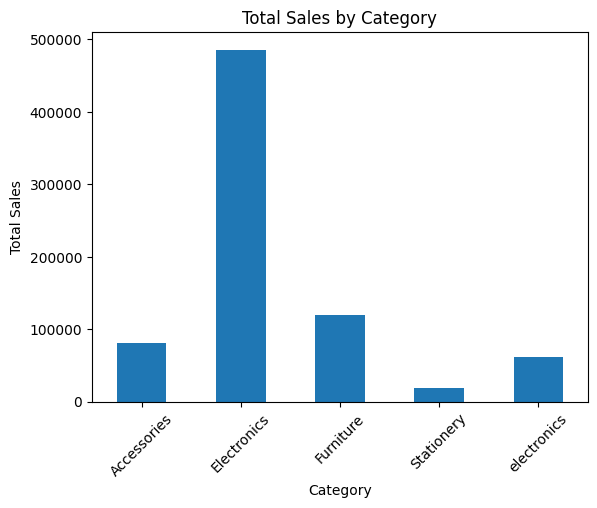

In [15]:
category_sales.plot(kind="bar")

plt.title("Total Sales by Category")
plt.xlabel("Category")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)

plt.show()

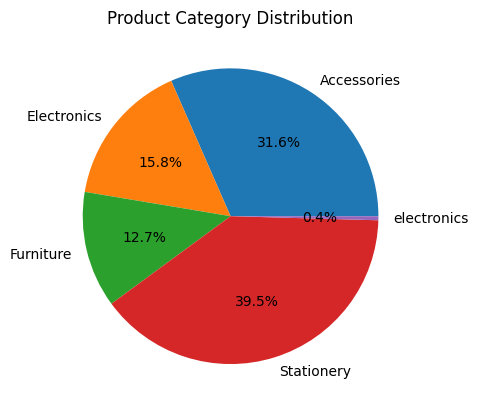

In [16]:
category_quantity = sales_data.groupby("Category")["Quantity"].sum()

category_quantity.plot(
    kind="pie",
    autopct="%1.1f%%"
)

plt.title("Product Category Distribution")
plt.ylabel("")

plt.show()

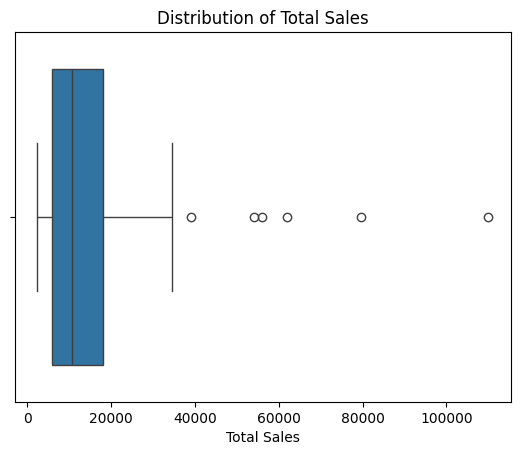

In [17]:
sns.boxplot(x=sales_data["Total_Sales"])

plt.title("Distribution of Total Sales")
plt.xlabel("Total Sales")

plt.show()